In [ ]:
!git clone https://github.com/declare-lab/MELD.git

fatal: destination path 'MELD' already exists and is not an empty directory.


In [ ]:
!ls MELD/

baseline  data	images	LICENSE  README.md  utils


In [ ]:
!ls MELD/data/

emorynlp  MELD	MELD_Dyadic  pickles


In [ ]:
!ls MELD/data/MELD/

datasets.yaml  dev_sent_emo.csv  test_sent_emo.csv  train_sent_emo.csv


In [ ]:
import pandas as pd
df = pd.read_csv('MELD/data/MELD/train_sent_emo.csv')
df.head()

,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my company’s tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So let’s talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


In [ ]:
print(df.shape)
print(df['Emotion'].value_counts())

(9989, 11)
Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64


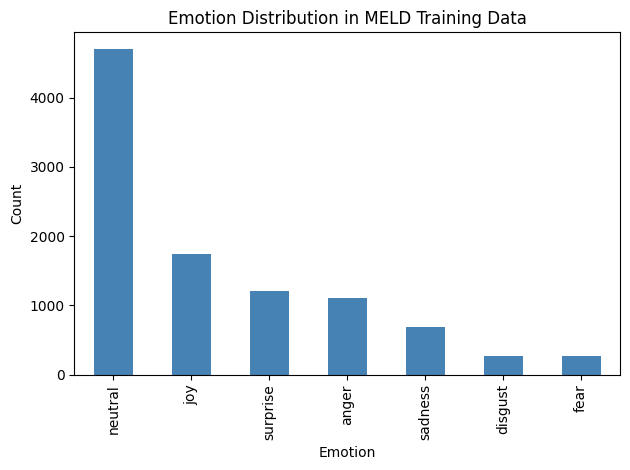

In [ ]:
import matplotlib.pyplot as plt

df['Emotion'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Emotion Distribution in MELD Training Data')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load train and test data
train_df = pd.read_csv('MELD/data/MELD/train_sent_emo.csv')
test_df = pd.read_csv('MELD/data/MELD/test_sent_emo.csv')

# Prepare text and labels
X_train = train_df['Utterance']
y_train = train_df['Emotion']

X_test = test_df['Utterance']
y_test = test_df['Emotion']

# Convert text to numbers using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

# Test the model
y_pred = model.predict(X_test_vec)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       anger       0.30      0.07      0.11       345
     disgust       1.00      0.01      0.03        68
        fear       0.00      0.00      0.00        50
         joy       0.49      0.22      0.30       402
     neutral       0.54      0.91      0.68      1256
     sadness       0.45      0.07      0.12       208
    surprise       0.53      0.40      0.46       281

    accuracy                           0.53      2610
   macro avg       0.47      0.24      0.24      2610
weighted avg       0.49      0.53      0.45      2610



In [ ]:
def predict_emotion(text):
    vec = vectorizer.transform([text])
    result = model.predict(vec)[0]
    print(f"Text: {text}")
    print(f"Predicted Emotion: {result}")

# Test with sentences
predict_emotion("I am so happy today!")
predict_emotion("I hate this so much.")
predict_emotion("I don't know what to say.")

Text: I am so happy today!
Predicted Emotion: joy
Text: I hate this so much.
Predicted Emotion: neutral
Text: I don't know what to say.
Predicted Emotion: neutral


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

print(torch.__version__)

2.11.0+cpu


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode emotion labels to numbers
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_vec.toarray(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_vec.toarray(), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_enc, dtype=torch.long)

print("Train size:", X_train_tensor.shape)
print("Test size:", X_test_tensor.shape)
print("Classes:", le.classes_)

Train size: torch.Size([9989, 5000])
Test size: torch.Size([2610, 5000])
Classes: ['anger' 'disgust' 'fear' 'joy' 'neutral' 'sadness' 'surprise']


In [ ]:
class EmotionNet(nn.Module):
    def __init__(self):
        super(EmotionNet, self).__init__()
        self.fc1 = nn.Linear(5000, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(256, 7)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

net = EmotionNet()
print(net)

EmotionNet(
  (fc1): Linear(in_features=5000, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=7, bias=True)
)


In [ ]:
# Setup
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)
dataset = TensorDataset(X_train_tensor, y_train_tensor)
loader = DataLoader(dataset, batch_size=64, shuffle=True)

# Train for 10 rounds
for epoch in range(10):
    net.train()
    total_loss = 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        output = net(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/10 - Loss: {total_loss/len(loader):.4f}")

Epoch 1/10 - Loss: 1.5920
Epoch 2/10 - Loss: 1.3541
Epoch 3/10 - Loss: 1.2029
Epoch 4/10 - Loss: 1.0794
Epoch 5/10 - Loss: 0.9670
Epoch 6/10 - Loss: 0.8777
Epoch 7/10 - Loss: 0.7987
Epoch 8/10 - Loss: 0.7447
Epoch 9/10 - Loss: 0.6869
Epoch 10/10 - Loss: 0.6482


In [ ]:
net.eval()
with torch.no_grad():
    output = net(X_test_tensor)
    predictions = torch.argmax(output, dim=1)
    correct = (predictions == y_test_tensor).sum().item()
    total = y_test_tensor.size(0)
    print(f"PyTorch Model Accuracy: {correct/total*100:.2f}%")

PyTorch Model Accuracy: 48.47%


In [ ]:
def predict_emotion_pytorch(text):
    net.eval()
    vec = vectorizer.transform([text])
    tensor = torch.tensor(vec.toarray(), dtype=torch.float32)
    with torch.no_grad():
        output = net(tensor)
        pred = torch.argmax(output, dim=1).item()
    print(f"Text: {text}")
    print(f"Predicted Emotion: {le.classes_[pred]}")
    print()

predict_emotion_pytorch("I am so happy today!")
predict_emotion_pytorch("I hate this so much.")
predict_emotion_pytorch("I don't know what to say.")
predict_emotion_pytorch("This is really scary!")

Text: I am so happy today!
Predicted Emotion: joy

Text: I hate this so much.
Predicted Emotion: disgust

Text: I don't know what to say.
Predicted Emotion: neutral

Text: This is really scary!
Predicted Emotion: surprise

